# **Model: Extracting Wav2Vec along with MelSpec Features**
 Here in this code, we use optuna and test multiple hyper parameters and tune the model to figure out which works better and efficiently.

In [3]:
# Importing all the necessary libraries for data processing, audio feature extraction,
# Here we just test the Wav2Vec Augmentation along with extracting the MelSpec Features:
import os
import librosa
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from transformers import Wav2Vec2Processor, Wav2Vec2ForSequenceClassification
import torch
from keras_tuner import RandomSearch
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Set the paths for the audio files and dataset labels.
# Define constants like sample rate and audio duration for consistent processing.
AUDIO_PATH = "/Users/ananya/Desktop/Final_Project/ASVspoof2021_DF_eval/Sample_Audio/"
CSV_FILE_PATH = "/Users/ananya/Desktop/Final_Project/ASVspoof2021_DF_eval/output_file.csv"
FEATURES_FILE = "/Users/ananya/Desktop/Final_Project/ASVspoof2021_DF_eval/extracted_features.csv"
SAMPLE_RATE = 16000
DURATION = 2  # seconds
SAMPLES_PER_TRACK = SAMPLE_RATE * DURATION

# This function creates variations of the original audio by adding noise, changing speed, or altering pitch.
# These augmentations help the model learn better by introducing diversity to the data.
def augment_audio(audio, sr=SAMPLE_RATE):
    """Generate augmented versions of the audio signal."""
    augmented_signals = [audio]

    # Add Gaussian noise
    noise = np.random.normal(0, 0.001, audio.shape)
    augmented_signals.append(audio + noise)

    # Time-stretch the audio
    augmented_signals.append(librosa.effects.time_stretch(audio, rate=1.1))
    augmented_signals.append(librosa.effects.time_stretch(audio, rate=0.9))

    # Pitch-shift the audio
    augmented_signals.append(librosa.effects.pitch_shift(audio, sr=sr, n_steps=2))
    augmented_signals.append(librosa.effects.pitch_shift(audio, sr=sr, n_steps=-2))

    return augmented_signals


# Load a pre-trained Wav2Vec2 model, which is designed to process audio and extract high-quality features.
# Freeze the feature encoder to prevent it from being modified during training.
print("Loading Wav2Vec2 model...")
processor = Wav2Vec2Processor.from_pretrained("facebook/wav2vec2-base")
wave2vec2_model = Wav2Vec2ForSequenceClassification.from_pretrained(
    "facebook/wav2vec2-base", num_labels=2
)
wave2vec2_model.freeze_feature_encoder()
wave2vec2_model.gradient_checkpointing_enable()
print("Wav2Vec2 model loaded successfully!")


# These functions extract features from audio signals, including MFCCs and Wav2Vec2 embeddings.
# Features are numerical representations of the audio that the model uses to learn.
def mfcc_with_deltas(signal, sr=SAMPLE_RATE, n_mfcc=13):
    """Extract MFCC, MFCC Delta, and Delta-Delta features."""
    mfcc_features = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=n_mfcc)
    mfcc_delta = librosa.feature.delta(mfcc_features)
    mfcc_delta_delta = librosa.feature.delta(mfcc_features, order=2)
    combined = np.hstack([mfcc_features.mean(axis=1), mfcc_delta.mean(axis=1), mfcc_delta_delta.mean(axis=1)])
    return combined

def extract_wave2vec_features(signal):
    """Extract Wav2Vec2 features."""
    inputs = processor(signal, sampling_rate=SAMPLE_RATE, return_tensors="pt", padding=True)
    with torch.no_grad():
        outputs = wave2vec2_model(**inputs)
    return outputs.logits.numpy().flatten()

def extract_features(signal, sr=SAMPLE_RATE):
    try:
        mfcc_features = mfcc_with_deltas(signal, sr)
        wave2vec_features = extract_wave2vec_features(signal)
        combined_features = np.hstack([mfcc_features, wave2vec_features])
        return (combined_features - np.mean(combined_features)) / np.std(combined_features)  # Normalize
    except Exception as e:
        print(f"Feature extraction error: {e}")
        return None



Loading Wav2Vec2 model...


/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/163 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.84k [00:00<?, ?B/s]

/usr/local/lib/python3.10/dist-packages/transformers/configuration_utils.py:306: UserWarning: Passing `gradient_checkpointing` to a config initialization is deprecated and will be removed in v5 Transformers. Using `model.gradient_checkpointing_enable()` instead, or if you are using the `Trainer` API, pass `gradient_checkpointing=True` in your `TrainingArguments`.
  warnings.warn(


vocab.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/380M [00:00<?, ?B/s]

Some weights of Wav2Vec2ForSequenceClassification were not initialized from the model checkpoint at facebook/wav2vec2-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'projector.bias', 'projector.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Wav2Vec2 model loaded successfully!


In [ ]:
# This function reads audio files and their labels, applies augmentations, extracts features, and saves them.
def load_audio_data(audio_path, csv_file_path, features_file, force_update=False):
    if os.path.exists(features_file) and not force_update:
        print(f"Loading precomputed features from {features_file}...")
        data = pd.read_csv(features_file)
        X = data.iloc[:, :-1].values
        y = data.iloc[:, -1].values
        print(f"Loaded {X.shape[0]} samples with {X.shape[1]} features each.")
        return X, y

    print("Extracting features from audio data...")
    labels_df = pd.read_csv(csv_file_path)
    X, y = [], []

    for _, row in labels_df.iterrows():
        file_name, label = row["filename"], row["label"]
        file_path = os.path.join(audio_path, file_name)
        if not os.path.exists(file_path):
            print(f"File {file_name} not found. Skipping...")
            continue

        audio, _ = librosa.load(file_path, sr=SAMPLE_RATE, duration=DURATION)
        audio = np.pad(audio, (0, max(0, SAMPLES_PER_TRACK - len(audio))), mode="constant")

        # Apply augmentation
        augmented_audios = augment_audio(audio)
        print(f"Generated {len(augmented_audios)} augmentations for {file_name}.")

        for augmented_audio in augmented_audios:
            features = extract_features(augmented_audio)
            if features is not None:
                X.append(features)
                y.append(1 if label == "bonafide" else 0)

    # Save the updated features to the file
    X_np, y_np = np.array(X), np.array(y)
    pd.DataFrame(np.hstack([X_np, y_np.reshape(-1, 1)])).to_csv(features_file, index=False)
    print(f"Updated features saved to {features_file}.")
    print(f"Extracted {X_np.shape[0]} samples with {X_np.shape[1]} features each.")
    return X_np, y_np

# Load Data
X, y = load_audio_data(AUDIO_PATH, CSV_FILE_PATH, FEATURES_FILE, force_update=False)


Loading precomputed features from /Users/ananya/Desktop/Final_Project/ASVspoof2021_DF_eval/extracted_features.csv...
Loaded 14772 samples with 54 features each.


In [ ]:

# Applying PCA reduces the number of features while retaining important information, making the model more efficient:
# Check the shape of X before applying PCA
print(f"Shape of feature matrix X: {X.shape}")

# Adjust PCA components dynamically ensuring it doesn't exceed samples or features
n_components = min(X.shape[0], X.shape[1], 128)
pca = PCA(n_components=n_components)
X = pca.fit_transform(X)

print(f"Shape of X after PCA: {X.shape}")

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Hyperparameter Tuning with Keras Tuner:
def build_model(hp):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train.shape[1],)),
        tf.keras.layers.Dense(hp.Int('units', min_value=256, max_value=512, step=32), activation="relu"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(hp.Float('dropout_1', min_value=0.2, max_value=0.2, step=0.1)),
        tf.keras.layers.Dense(hp.Int('units_2', min_value=128, max_value=256, step=32), activation="relu"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(hp.Float('dropout_2', min_value=0.2, max_value=0.2, step=0.1)),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(hp.Choice('learning_rate', values=[1e-3, 1e-4, 1e-5])),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

Shape of feature matrix X: (14772, 54)
Shape of X after PCA: (14772, 54)


In [ ]:
# Figuring out the best parameters to test out my model:
learning_rates = [1e-3, 1e-4, 5e-5]
best_lr = None
best_accuracy = 0
results = {}

for lr in learning_rates:
    print(f"Testing learning rate: {lr}")

    # Define and compile the model
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train.shape[1],)),
        tf.keras.layers.Dense(512, activation="relu"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy",
                  metrics=["accuracy"])

    # Train the model
    history = model.fit(
        X_train, y_train,
        validation_split=0.2,
        epochs=150,  # You can reduce epochs for faster tuning
        batch_size=32,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)
        ],
        verbose=1
    )

    # Evaluate the model
    y_pred = (model.predict(X_test) > 0.5).astype("int32")
    accuracy = accuracy_score(y_test, y_pred)
    print(f"Accuracy for learning rate {lr}: {accuracy}")
    results[lr] = accuracy

    # Track the best learning rate
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_lr = lr

print("\nBest learning rate:", best_lr)
print("Results:", results)


Testing learning rate: 0.001
Epoch 1/150
296/296 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7062 - loss: 0.6136 - val_accuracy: 0.6362 - val_loss: 0.6176
Epoch 2/150
296/296 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7837 - loss: 0.4756 - val_accuracy: 0.8105 - val_loss: 0.4404
Epoch 3/150
296/296 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7919 - loss: 0.4464 - val_accuracy: 0.8160 - val_loss: 0.4146
Epoch 4/150
296/296 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8182 - loss: 0.4046 - val_accuracy: 0.8367 - val_loss: 0.3807
Epoch 5/150
296/296 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8335 - loss: 0.3743 - val_accuracy: 0.8507 - val_loss: 0.3468
Epoch 6/150
296/296 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8475 - loss: 0.3522 - val_accuracy: 0.8464 - val_loss: 0.3630
Epoch 7/150
296/296 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8497 - loss: 0.3403 - val_accuracy: 0.8558 - val_loss: 0.3505
Epoch 8/150
296/296 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8

# **Model :** Utilizing the best hyperparameters to test out the model.
**Accuracy:** 92.01%

In [ ]:
# Utilizing the best hyperparameters to test out the model:
# Hyperparameter Search
tuner = RandomSearch(
    build_model,
    objective="val_accuracy",
    max_trials=10,
    executions_per_trial=2,
    directory="hyperparam_tuning",
    project_name="audio_classification"
)
tuner.search(X_train, y_train, epochs=10, validation_split=0.2)



# Best Hyperparameters
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print(f"Best Hyperparameters: {best_hps.values}")

# Build and Train Final Model
model = tuner.hypermodel.build(best_hps)
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=35, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=35)
]
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=150,
    batch_size=32,
    callbacks=callbacks
)


Reloading Tuner from hyperparam_tuning/audio_classification/tuner0.json
Best Hyperparameters: {'units': 320, 'dropout_1': 0.2, 'units_2': 64, 'dropout_2': 0.2, 'learning_rate': 0.01}
Epoch 1/150
296/296 ━━━━━━━━━━━━━━━━━━━━ 1s 882us/step - accuracy: 0.7350 - loss: 0.5724 - val_accuracy: 0.7728 - val_loss: 0.5212 - learning_rate: 0.0100
Epoch 2/150
296/296 ━━━━━━━━━━━━━━━━━━━━ 0s 615us/step - accuracy: 0.7760 - loss: 0.4743 - val_accuracy: 0.7923 - val_loss: 0.4559 - learning_rate: 0.0100
Epoch 3/150
296/296 ━━━━━━━━━━━━━━━━━━━━ 0s 659us/step - accuracy: 0.8040 - loss: 0.4439 - val_accuracy: 0.7936 - val_loss: 0.4450 - learning_rate: 0.0100
Epoch 4/150
296/296 ━━━━━━━━━━━━━━━━━━━━ 0s 607us/step - accuracy: 0.8155 - loss: 0.4149 - val_accuracy: 0.8274 - val_loss: 0.3986 - learning_rate: 0.0100
Epoch 5/150
296/296 ━━━━━━━━━━━━━━━━━━━━ 0s 636us/step - accuracy: 0.8200 - loss: 0.4096 - val_accuracy: 0.8219 - val_loss: 0.4047 - learning_rate: 0.0100
Epoch 6/150
296/296 ━━━━━━━━━━━━━━━━━━━━ 0

Best Hyperparameters:
{'units': 320, 'dropout_1': 0.2, 'units_2': 64, 'dropout_2': 0.2, 'learning_rate': 0.01}


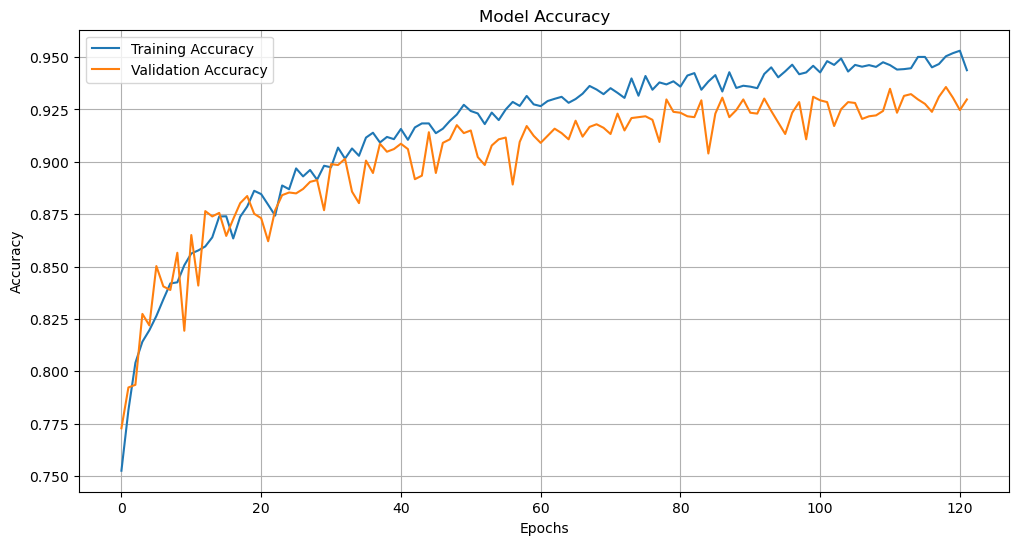

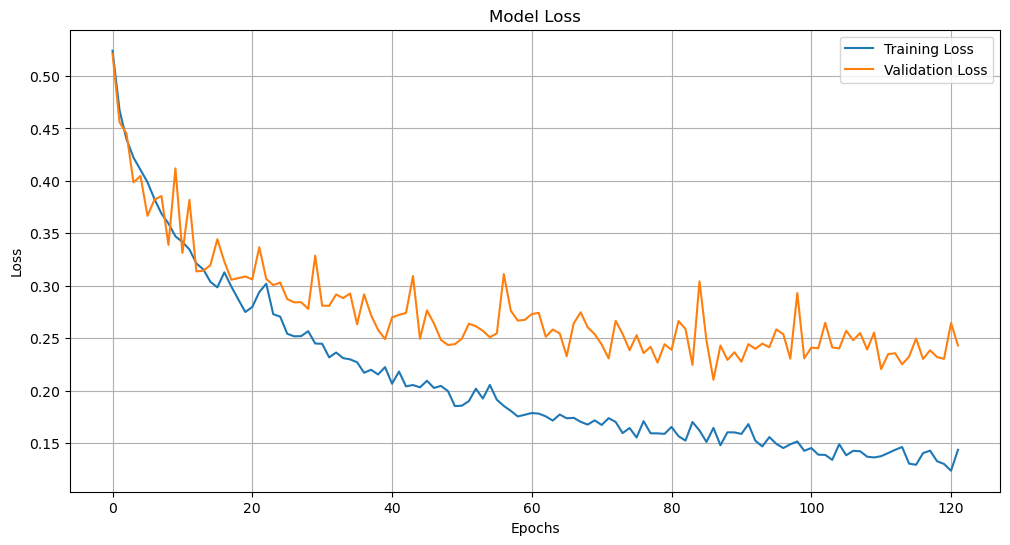

93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 497us/step


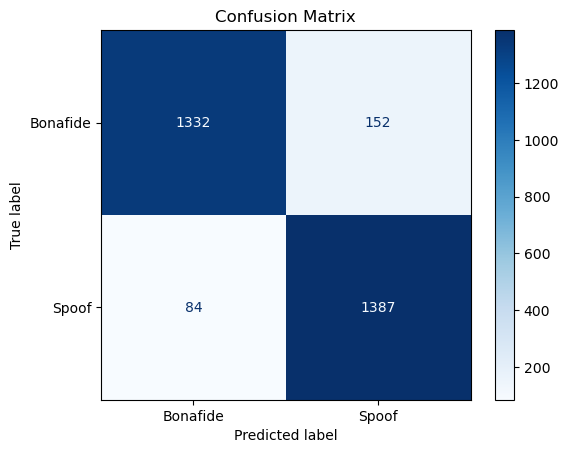

Classification Report:
              precision    recall  f1-score   support

         0.0       0.94      0.90      0.92      1484
         1.0       0.90      0.94      0.92      1471

    accuracy                           0.92      2955
   macro avg       0.92      0.92      0.92      2955
weighted avg       0.92      0.92      0.92      2955

Accuracy: 0.9201353637901861


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score

# Plot Training History
def plot_training_history(history):
    """Plots the training and validation accuracy/loss for the final model."""
    # Accuracy Plot
    plt.figure(figsize=(12, 6))
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Loss Plot
    plt.figure(figsize=(12, 6))
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

# Generate Confusion Matrix
def plot_confusion_matrix(model, X_test, y_test):
    """Generates and displays the confusion matrix."""
    y_pred = (model.predict(X_test) > 0.5).astype("int32")
    conf_matrix = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=["Bonafide", "Spoof"])
    disp.plot(cmap=plt.cm.Blues)
    plt.title("Confusion Matrix")
    plt.grid(False)
    plt.show()

    # Print classification report and accuracy
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    print("Accuracy:", accuracy_score(y_test, y_pred))

# After Hyperparameter Search and Training
print("Best Hyperparameters:")
print(best_hps.values)

# Plot the training history for the final model
plot_training_history(history)

# Evaluate and plot confusion matrix
plot_confusion_matrix(model, X_test, y_test)


# Selecting the best hyperparameters and training the model.

---


1.   **Average Training Accuracy:** 83.28%
2. **Average Validation Accuracy:** 86.15%
3. **Overall Average Accuracy:** 84.72%


In [ ]:

# Hyperparameter Search
tuner = RandomSearch(
    build_model,
    objective="val_accuracy",
    max_trials=20,
    executions_per_trial=2,
    directory="hyperparam_tuning",
    project_name="audio_classification"
)
tuner.search(X_train, y_train, epochs=50, validation_split=0.2)



# Best Hyperparameters
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print(f"Best Hyperparameters: {best_hps.values}")

# Build and Train Final Model
model = tuner.hypermodel.build(best_hps)
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=45, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=45)
]
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=150,
    batch_size=32,
    callbacks=callbacks
)


Reloading Tuner from hyperparam_tuning/audio_classification/tuner0.json
Best Hyperparameters: {'units': 256, 'dropout_1': 0.2, 'units_2': 64, 'dropout_2': 0.30000000000000004, 'learning_rate': 0.01}
Epoch 1/150
296/296 ━━━━━━━━━━━━━━━━━━━━ 1s 857us/step - accuracy: 0.7093 - loss: 0.6170 - val_accuracy: 0.7847 - val_loss: 0.5157 - learning_rate: 0.0100
Epoch 2/150
296/296 ━━━━━━━━━━━━━━━━━━━━ 0s 601us/step - accuracy: 0.7804 - loss: 0.4779 - val_accuracy: 0.7881 - val_loss: 0.4489 - learning_rate: 0.0100
Epoch 3/150
296/296 ━━━━━━━━━━━━━━━━━━━━ 0s 580us/step - accuracy: 0.7993 - loss: 0.4584 - val_accuracy: 0.7927 - val_loss: 0.4395 - learning_rate: 0.0100
Epoch 4/150
296/296 ━━━━━━━━━━━━━━━━━━━━ 0s 561us/step - accuracy: 0.8051 - loss: 0.4315 - val_accuracy: 0.8198 - val_loss: 0.4166 - learning_rate: 0.0100
Epoch 5/150
296/296 ━━━━━━━━━━━━━━━━━━━━ 0s 554us/step - accuracy: 0.8138 - loss: 0.4184 - val_accuracy: 0.8299 - val_loss: 0.3893 - learning_rate: 0.0100
Epoch 6/150
296/296 ━━━━━━

Best Hyperparameters:
{'units': 256, 'dropout_1': 0.2, 'units_2': 64, 'dropout_2': 0.30000000000000004, 'learning_rate': 0.01}


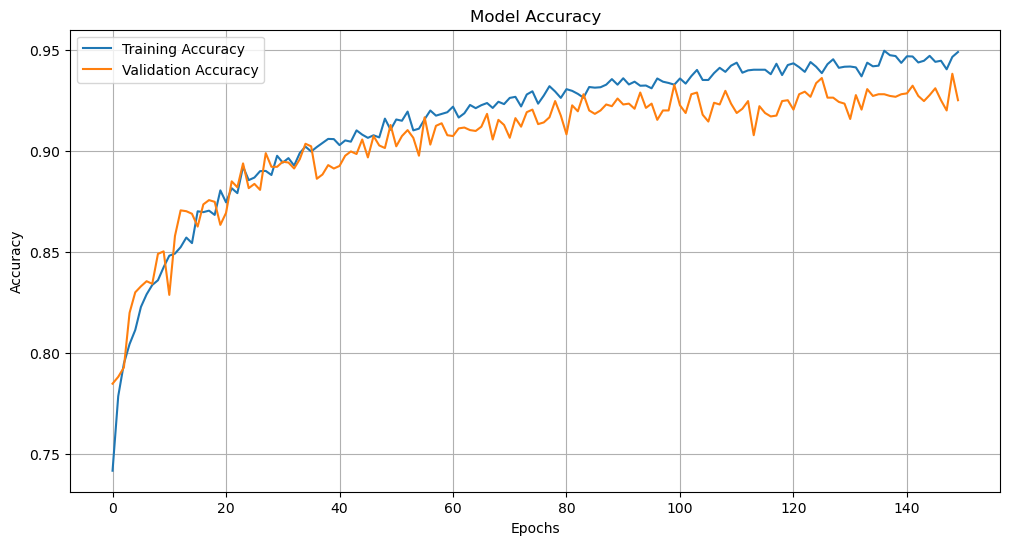

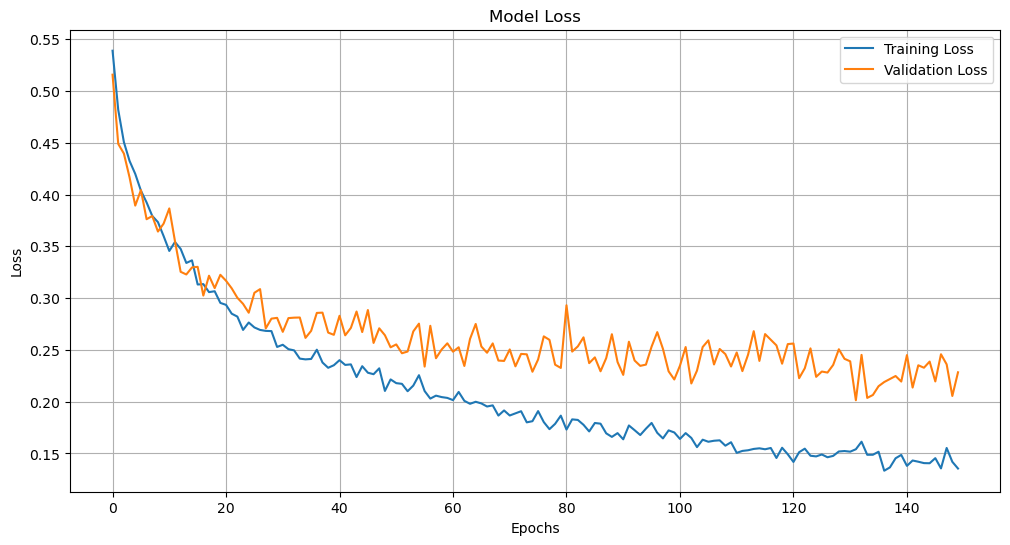

93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 501us/step


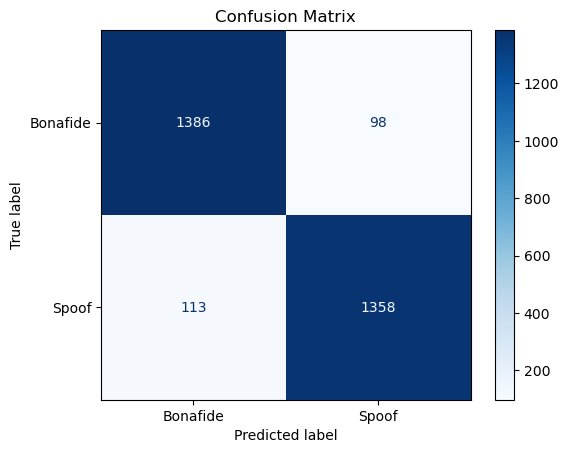

Classification Report:
              precision    recall  f1-score   support

         0.0       0.92      0.93      0.93      1484
         1.0       0.93      0.92      0.93      1471

    accuracy                           0.93      2955
   macro avg       0.93      0.93      0.93      2955
weighted avg       0.93      0.93      0.93      2955

Accuracy: 0.9285956006768189


In [ ]:
# Plotting the accuracy & Validation of the best hyperparameters which were used:
# Plotting confusion matrix
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score

# Plot Training History
def plot_training_history(history):
    """Plots the training and validation accuracy/loss for the final model."""
    # Accuracy Plot
    plt.figure(figsize=(12, 6))
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Loss Plot
    plt.figure(figsize=(12, 6))
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

# Generate Confusion Matrix
def plot_confusion_matrix(model, X_test, y_test):
    """Generates and displays the confusion matrix."""
    y_pred = (model.predict(X_test) > 0.5).astype("int32")
    conf_matrix = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=["Bonafide", "Spoof"])
    disp.plot(cmap=plt.cm.Blues)
    plt.title("Confusion Matrix")
    plt.grid(False)
    plt.show()

    # Print classification report and accuracy
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    print("Accuracy:", accuracy_score(y_test, y_pred))

# After Hyperparameter Search and Training
print("Best Hyperparameters:")
print(best_hps.values)

# Plot the training history for the final model
plot_training_history(history)

# Evaluate and plot confusion matrix
plot_confusion_matrix(model, X_test, y_test)
